# **AISO Learning unit 5: Simple Hillclimbing**
# How to implement Simple Hillclimbing Search in Python
Hill Climbing is a heuristic search often used for mathematical optimisation problems in the field of Artificial Intelligence. 

Given a large set of inputs and a good heuristic function, the algorithm tries to find the best possible solution to the problem in the most reasonable time period. T

This notebook will focus on the simpliest form of Hill Climbing. 

Simple Hill Climbing is the simplest way to implement a hill climbing algorithm. It only evaluates the neighbour node state at a time and selects the first one which optimizes current cost and set it as a current state. It only checks it’s one successor state, and if it finds better than the current state, then it moves to that state else it remains in the same state. This algorithm has the following features:

* Less time consuming
* Less optimal solution
* The solution is not guaranteed

## Features of Hill Climbing
### It carries out a Heuristic search
A heuristic function is one that ranks all the potential alternatives in a search algorithm based on the information available. It helps the algorithm to select the best route to its solution. This basically means that this search algorithm may not find the optimal solution to the problem but it will give the best possible solution in a reasonable amount of time.

### It is a variant of the generate-and-test algorithm
Hill climbing takes the feedback from the test procedure and the generator uses it in deciding the next move in the search space. The algorithm is as follows :

**Step 1**: Generate possible solutions <br /> 
**Step 2**: Evaluate to see if this is the expected solution <br />
**Step 3**: If the solution has been found quit else go back to **Step 1** <br />

### It uses the Greedy approach
At any point in state space, the search moves in that direction only which optimises the cost of function with the hope of finding the most optimum solution at the end.


##  Lets Understand the Problem !!

We want to transform one valid English word **`EAST`** into another valid English word **`EATS`** by **swapping letters**. *.

We’ll use the **Simple Hill Climbing Algorithm** to find the goal.


## The Simple Hill Climbing Search Algorithm
**Step 0**: Generate a initial state, it can be manually or random <br />
**Step 1**: Evaluate the initial state, if it is goal state then return success and STOP <br />
**Step 2**: Loop Until a solution is found or there is no new operator left to apply<br />
>**Step 3**: Select and apply an operator to the current state <br />
>**Step 4**: Check new state:
> - If it is goal state, then return success and STOP.
> - else if it is better than the current state then set current state to new state

**Step 5**: STOP<br />

In [1]:
import itertools

# small dictionary of valid words
WORDS = {"EAST", "EATS"}

def score(word, goal):
    """Heuristic: number of letters in correct position."""
    return sum(a == b for a, b in zip(word, goal))

def neighbors(word):
    """Generate neighbors by swapping two letters (valid words only)."""
    for i, j in itertools.combinations(range(len(word)), 2):
        w = list(word)
        w[i], w[j] = w[j], w[i]
        cand = "".join(w)
        print(cand)
        if cand in WORDS and cand != word:
            yield cand

def simple_hill_climb(start, goal):
    current = start
    current_score = score(current, goal)
    print(f"Start: {current} | Score: {current_score}")

    improved = True
    while improved:
        improved = False
        for nb in neighbors(current):  # check one by one
            s = score(nb, goal)
            if s > current_score:
                current, current_score = nb, s
                improved = True
                print(f"Move to: {current} | Score: {current_score}")
                break  # <-- move immediately (simple hill climbing)
        if not improved:
            print(f"Stop: local optimum at '{current}' | Score: {current_score}")

    if current == goal:
        print(f"Goal reached: {goal}")

# Run it
simple_hill_climb("EAST", "EATS")


Start: EAST | Score: 2
AEST
SAET
TASE
ESAT
ETSA
EATS
Move to: EATS | Score: 4
AETS
TAES
SATE
ETAS
ESTA
EAST
Stop: local optimum at 'EATS' | Score: 4
Goal reached: EATS


## **Another Example of Random Start Hill Climbing Implementation**
### Problem: 
Find an 8-bit number matching a hidden target. A state is a list of bits, a neighbour is the same bits with one flipped, and fitness is -|value - target| (0 is perfect).

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt

N_BITS, TARGET = 8, 173          # 173 = 10101101

def value(bits):     return int("".join(map(str, bits)), 2) # Calculate the binary number towards denary representation
    
def fitness(bits):   return -abs(value(bits) - TARGET)  # Calculate the fitness of the solution

def neighbours(bits):  # Produce all possible neighbours and return them in an iterable (list)
    for i in range(len(bits)):
        n = bits.copy(); n[i] ^= 1
        yield n

def hill_climb(bits):
    path = [bits]
    while True:
        best = max(neighbours(bits), key=fitness)
        if fitness(best) <= fitness(bits):   # no neighbour is better -> stop 
            return path
        bits = best
        path.append(bits)

In [4]:
## Change the value of the random seed below and see how the outputs are different (for instance try seed = 4)
random.seed(1)
start = [random.randint(0, 1) for _ in range(N_BITS)] # Produce a random initial state
path = hill_climb(start)

# Print the results
for step, b in enumerate(path):
    print(f"step {step}: {''.join(map(str, b))}  value={value(b):3d}  fitness={fitness(b)}")

step 0: 00101111  value= 47  fitness=-126
step 1: 10101111  value=175  fitness=-2
step 2: 10101101  value=173  fitness=0


## **Another Example of Random Start Hill Climbing Implementation**
So, here’s a basic skeleton of the solution for a simple problem. One more problem we will use to illustrate how the hill climber works is to move from a random initial string to the target string ***Hello, World!*** by randomly changing one character in the current solution to a random alternative character. The solution evaluation makes use of a distance measure. This is a measure is the sum of the difference of each character (using its ASCII code) in the current solution from that in the target string, e.g. assuming a target string **Dave**, **Cove** has a distance measure of 15 because **o** is 14 places in ASCII from **a** and, **C** is 1 place from **D**. Since the optimal solution will have an distance of 0, this problem is a minimisation problem. Trivial to solve but a good introduction to how the algorithm works.

## Hill Climbing Algorithm

The `hill_climber` function is the core of the algorithm. It starts with the random initial string, evaluates its distance from the target, and iteratively performs the following steps:

1. Generates a mutated string (neighbor).
2. Checks if the mutated string is closer to the target by having a lower distance.
3. If the mutated string improves the distance, it becomes the new current solution, and the process repeats until the target is reached.


In [5]:
import random 
import string 

# This function returns a random initial solution from which the search begins
def generate_random_solution(length=13): 
    return [random.choice(string.printable) for _ in range(length)] 

# This function calculates how far each character in the current 
# solution is from the target solution
def evaluate(solution, target="Hello, World!"): 
    target = list(target) 
    diff = 0
    for i in range(len(target)): 
        s = solution[i] 
        t = target[i] 
        diff += abs(ord(s) - ord(t)) 
    return diff 

#Mutation introduces variety in each step, enabling the hill climber algorithm to explore different 
#possibilities instead of getting stuck on a single solution. 
#If the mutated string is closer to the target, the algorithm accepts it as the new current solution.

def mutate_solution(solution): 
    index = random.randint(0, len(solution) - 1) 
    solution[index] = random.choice(string.printable) 

# This is the main algorithm which repeatedly mutates the current solution
# and evaluates the result to see if it reduces the edit distance, i.e. finds
# a solution closer to the target
def simplehillclimbing():
    best = generate_random_solution() 
    best_score = evaluate(best) 
    scores = list()
    mutations = 0
    while True: 
        print('Best score so far', best_score, 'Solution', "".join(best)) 
 
        if best_score == 0: 
            break
 
        new_solution = list(best) 
        mutate_solution(new_solution) 
        mutations += 1
         
        score = evaluate(new_solution) 
        if evaluate(new_solution) < best_score: 
            best = new_solution 
            best_score = score
            # keep track of scores
            scores.append(best_score)
    return (scores, mutations)    

scores, mutations = simplehillclimbing()

0`Vyscore so far 628 Solution qc!3NT:
0`Vyscore so far 628 Solution qc!3NT:
d`Vyscore so far 576 Solution qc!3NT:
d`Vyscore so far 543 Solution qc!3N3:
d`Vyscore so far 523 Solution 3c!3N3:
d`Vyscore so far 523 Solution 3c!3N3:
d`Vyscore so far 507 Solution Mc!3N3:
drVyscore so far 501 Solution Mc!3N3:
drVyscore so far 501 Solution Mc!3N3:
drVyscore so far 501 Solution Mc!3N3:
drVyscore so far 501 Solution Mc!3N3:
Best score so far 480 Solution Mc!3N3:"drVy
Best score so far 385 Solution Mc!3N3:"tdrVy
Best score so far 385 Solution Mc!3N3:"tdrVy
Best score so far 385 Solution Mc!3N3:"tdrVy
Best score so far 351 Solution Mc!3N3:"tdrVW
Best score so far 351 Solution Mc!3N3:"tdrVW
Best score so far 335 Solution Mc!3N3*"tdrVW
Best score so far 335 Solution Mc!3N3*"tdrVW
Best score so far 307 Solution Mc=3N3*"tdrVW
Best score so far 307 Solution Mc=3N3*"tdrVW
Best score so far 307 Solution Mc=3N3*"tdrVW
Best score so far 307 Solution Mc=3N3*"tdrVW
Best score so far 307 Solution 

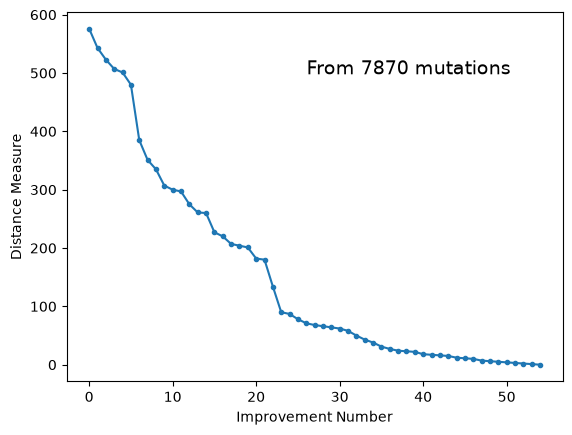

In [6]:
from matplotlib import pyplot

# line plot of best distance measures
pyplot.plot(scores, '.-')
pyplot.xlabel('Improvement Number')
pyplot.ylabel('Distance Measure')
pyplot.figtext(0.5, 0.75, 'From {0} mutations'.format(mutations), fontsize = 14)
pyplot.show()

It can be seen from this plot that there is a steady improvement in distance measure as the iterations increase. The initial distance is high (usually over 400 depending on the random initial string). The simple hill climber edges closer and closer with each improvement. However, as can be seen from the plot there are many more attempts than improvements. This indicates how inefficient this algorithm can be for search problems when there is no extra information used within the search itself.

<div style="background-color: #e0f7fa; padding: 15px; border-radius: 5px;">

### Task 1- Hill Climbing to Reach a Target Number

Start with a random number between 0 and 100, aiming to reach the target number (e.g., 42). At each step, increase or decrease the current number by 1, whichever brings it closer to the target. Continue this process until the current number matches the target. Track each step to observe how the number converges toward the target. This task demonstrates hill climbing by iteratively reducing the "distance" to the goal.
</div>
  

In [14]:
import random 
import string 

# This function returns a random initial solution from which the search begins
def generate_random_solution(length=13): 
    return random.randint(0,101)

# This function calculates how far each character in the current 
# solution is from the target solution
def evaluate(solution, target=42): 
    #target = list(target) 
    diff = abs(solution - target)
    #diff += abs(ord(s) - ord(t)) 
    return diff 

#Mutation introduces variety in each step, enabling the hill climber algorithm to explore different 
#possibilities instead of getting stuck on a single solution. 
#If the mutated string is closer to the target, the algorithm accepts it as the new current solution.

def mutate_solution(solution): 
    #index = random.randint(0, len(solution) - 1) 
    solution = random.randint(0,101)

# This is the main algorithm which repeatedly mutates the current solution
# and evaluates the result to see if it reduces the edit distance, i.e. finds
# a solution closer to the target
def simplehillclimbing():
    best = generate_random_solution() 
    best_score = evaluate(best) 
    scores = list()
    mutations = 0
    while True: 
        print('Best score so far', best_score, 'Solution', "".join(str(best))) 
 
        if best_score == 0: 
            break
 
        new_solution = best 
        mutate_solution(new_solution) 
        new_solution = random.randint(0,101)
        mutations += 1
         
        score = evaluate(new_solution) 
        
        if evaluate(new_solution) < best_score: 
            best = new_solution 
            best_score = score
            # keep track of scores
            scores.append(best_score)
    
    return (scores, mutations)    

scores, mutations = simplehillclimbing()

Best score so far 9 Solution 33
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best score so far 2 Solution 40
Best sco